**For generating plots using Wandb csv.file**

In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import os
import numpy as np

try:
    import ipywidgets as widgets
    print("'ipywidgets' is already installed")
except ImportError:
    print("'ipywidgets' not found. Installing now...")
    import sys
    import subprocess
    # 현재 실행 중인 커널의 환경에 정확히 설치하기 위해 sys.executable을 사용합니다.
    subprocess.check_call([sys.executable, "-m", "pip", "install", "ipywidgets"])
    import ipywidgets as widgets
    print("'ipywidgets' is installed successfully.")
    
from IPython.display import display, clear_output

'ipywidgets' is already installed


In [12]:
from scipy import stats as _scipy_stats

def mann_whitney_u_test(config_a, config_b, window_size=50, last_n=100, alpha=0.05, verbose=True):
    """
    두 알고리즘의 성능을 Mann-Whitney U test로 비교합니다.
    (RL 논문 표준 방식)

    Parameters
    ----------
    config_a, config_b : list of dict   (plot() 함수와 동일한 형식)
        각 dict:
          - path     : str,  CSV 파일 경로
          - label    : str,  범례 레이블
          - keyword  : str,  컬럼 매칭 키워드 (예: 'PCI_rippo', 'mappo')
          - exclude  : str,  제외할 키워드 (optional)
    window_size : int   평활화 롤링 윈도우 크기 (기본값 50)
    last_n      : int   비교에 사용할 마지막 N 포인트 평균 (기본값 100)
    alpha       : float 유의수준 (기본값 0.05)
    verbose     : bool  상세 출력 여부 (기본값 True)

    Returns
    -------
    dict  검정 결과 (stat, p_value, effect_size, mean/std of each group, significant)
          혹은 None (데이터 없을 때)
    """
    def _extract(config):
        all_vals = []
        for entry in config:
            file_path = entry['path']
            keyword   = entry.get('keyword', 'success_rate')
            exclude   = entry.get('exclude', None)

            try:
                df = pd.read_csv(file_path)
            except FileNotFoundError:
                print(f'[WARN] 파일을 찾을 수 없음: {file_path}')
                continue

            # --- plot() 함수와 동일한 컬럼 매칭 규칙 ---
            clean_kw = keyword.lower().replace('_', '').replace('-', '')
            cols = []
            for col in df.columns:
                col_lower = col.lower()
                if 'success_rate' not in col_lower:
                    continue
                clean_col = col_lower.replace('_', '').replace('-', '')
                if clean_kw not in clean_col:
                    continue
                if 'MIN' in col or 'MAX' in col or '_step' in col:
                    continue
                if exclude and exclude.lower() in col_lower:
                    continue
                cols.append(col)

            if not cols:
                print(f'[WARN] 키워드 "{keyword}" 매칭 컬럼 없음: {file_path}')
                continue

            # 시드별 최종 성능값 추출
            for col in cols:
                series  = df[col].dropna()
                smoothed = series.rolling(window=window_size, min_periods=1).mean()
                val = smoothed.tail(last_n).mean() if last_n and last_n > 0 else smoothed.iloc[-1]
                all_vals.append(float(val))

        return np.array(all_vals)

    data_a = _extract(config_a)
    data_b = _extract(config_b)

    if len(data_a) == 0 or len(data_b) == 0:
        print('[ERROR] 데이터가 없어 검정을 수행할 수 없습니다.')
        return None

    # --- Mann-Whitney U test (양측) ---
    # stat은 data_a에 대한 U_A 값입니다.
    u_a, p_value = _scipy_stats.mannwhitneyu(data_a, data_b, alternative='two-sided')

    n_a, n_b = len(data_a), len(data_b)
    
    # U_B 계산 및 더 작은 U 값 도출
    u_b = (n_a * n_b) - u_a
    stat_min = min(u_a, u_b)

    # 효과 크기: rank-biserial correlation
    # 주의: 방향성(부호)을 잃지 않기 위해 stat_min이 아닌 u_a를 사용하여 계산합니다.
    # 양수면 data_a가 우세, 음수면 data_b가 우세함을 나타냅니다.
    effect_size = 1.0 - (2.0 * u_a) / (n_a * n_b)

    label_a = config_a[0].get('label', 'Algorithm A') if config_a else 'Algorithm A'
    label_b = config_b[0].get('label', 'Algorithm B') if config_b else 'Algorithm B'

    significant = bool(p_value < alpha)

    # --- 결과 출력 ---
    if verbose:
        print('=' * 60)
        print(f'Mann-Whitney U Test: {label_a} vs {label_b}')
        print(f'  N : {label_a}={n_a}, {label_b}={n_b}')
        print(f'  U 통계량 (Smaller U): {stat_min:.4f}  (U_a={u_a:.4f}, U_b={u_b:.4f})')
        print(f'  p-값       : {p_value:.4f}')
        print(f'  효과 크기 (rank-biserial r): {effect_size:.4f}')
        print(f'  평균 {label_a}: {np.mean(data_a):.4f} ± {np.std(data_a):.4f}')
        print(f'  평균 {label_b}: {np.mean(data_b):.4f} ± {np.std(data_b):.4f}')
        if significant:
            winner = label_a if np.mean(data_a) > np.mean(data_b) else label_b
            print(f'  결과: 유의함 (p={p_value:.4f} < α={alpha})')
            print(f'  → {winner} 가 통계적으로 유의하게 더 좋은 성능을 보임')
        else:
            print(f'  결과: 유의하지 않음 (p={p_value:.4f} ≥ α={alpha})')
        print('=' * 60)

    return {
        'label_a':     label_a,
        'label_b':     label_b,
        'data_a':      data_a,
        'data_b':      data_b,
        'stat':        stat_min, # Return value도 stat_min으로 변경
        'p_value':     p_value,
        'effect_size': effect_size,
        'mean_a':      float(np.mean(data_a)),
        'std_a':       float(np.std(data_a)),
        'mean_b':      float(np.mean(data_b)),
        'std_b':       float(np.std(data_b)),
        'n_a':         n_a,
        'n_b':         n_b,
        'significant': significant,
        'alpha':       alpha,
    }


def plot_mann_whitney(results, figsize=(7, 5), ylim=None):
    """
    mann_whitney_u_test() 결과를 박스플롯으로 시각화합니다.

    Parameters
    ----------
    results : dict   mann_whitney_u_test() 반환값
    figsize : tuple  그래프 크기
    ylim    : tuple  y축 범위 (optional)
    """
    if results is None:
        print('[ERROR] 유효한 검정 결과가 없습니다.')
        return

    plt.close('all')
    plt.rc('font', size=14)
    plt.rc('axes', labelsize=14)
    plt.rc('xtick', labelsize=14)
    plt.rc('ytick', labelsize=14)
    plt.rc('legend', fontsize=14)

    fig, ax = plt.subplots(figsize=figsize)

    data_a  = results['data_a']
    data_b  = results['data_b']
    label_a = results['label_a']
    label_b = results['label_b']
    p_value = results['p_value']
    alpha   = results['alpha']

    # 박스플롯
    bp = ax.boxplot(
        [data_a, data_b],
        labels=[label_a, label_b],
        patch_artist=True,
        medianprops=dict(color='black', linewidth=2),
    )
    colors = ['#2196F3', '#FF5722']
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)

    # 유의성 마커 (* / ** / ***)
    if results['significant']:
        y_max   = max(float(max(data_a)), float(max(data_b)))
        y_min   = min(float(min(data_a)), float(min(data_b)))
        y_range = (y_max - y_min) if y_max != y_min else 0.1
        y_sig   = y_max + y_range * 0.12

        ax.plot([1, 2], [y_sig, y_sig], 'k-', linewidth=1.5)
        ax.plot([1, 1], [y_sig - y_range * 0.04, y_sig], 'k-', linewidth=1.5)
        ax.plot([2, 2], [y_sig - y_range * 0.04, y_sig], 'k-', linewidth=1.5)

        if p_value < 0.001:
            sig_text = '***'
        elif p_value < 0.01:
            sig_text = '**'
        else:
            sig_text = '*'

        ax.text(1.5, y_sig + y_range * 0.02, sig_text,
                ha='center', va='bottom', fontsize=18, fontweight='bold')

    sig_str = '유의함' if results['significant'] else '유의하지 않음'
    ax.set_ylabel('Success Rate')
    ax.set_title(
        f'Mann-Whitney U Test\n'
        f'p = {p_value:.4f}  ({sig_str})',
        fontsize=13,
    )
    ax.grid(True, linestyle='--', alpha=0.5)

    if ylim is not None:
        ax.set_ylim(ylim)

    plt.tight_layout()
    plt.show()
    plt.close(fig)

Mann-Whitney U Test: PCI-IPPO vs IPPO
  N : PCI-IPPO=5, IPPO=5
  U 통계량 (Smaller U): 0.0000  (U_a=25.0000, U_b=0.0000)
  p-값       : 0.0079
  효과 크기 (rank-biserial r): -1.0000
  평균 PCI-IPPO: 0.7613 ± 0.0912
  평균 IPPO: 0.1290 ± 0.0571
  결과: 유의함 (p=0.0079 < α=0.05)
  → PCI-IPPO 가 통계적으로 유의하게 더 좋은 성능을 보임
Mann-Whitney U Test: PCI-IPPO vs MAPPO
  N : PCI-IPPO=5, MAPPO=5
  U 통계량 (Smaller U): 1.0000  (U_a=24.0000, U_b=1.0000)
  p-값       : 0.0159
  효과 크기 (rank-biserial r): -0.9200
  평균 PCI-IPPO: 0.7613 ± 0.0912
  평균 MAPPO: 0.4597 ± 0.2068
  결과: 유의함 (p=0.0159 < α=0.05)
  → PCI-IPPO 가 통계적으로 유의하게 더 좋은 성능을 보임
Mann-Whitney U Test: PCI-MAPPO vs IPPO
  N : PCI-MAPPO=5, IPPO=5
  U 통계량 (Smaller U): 0.0000  (U_a=25.0000, U_b=0.0000)
  p-값       : 0.0079
  효과 크기 (rank-biserial r): -1.0000
  평균 PCI-MAPPO: 0.7091 ± 0.0181
  평균 IPPO: 0.1290 ± 0.0571
  결과: 유의함 (p=0.0079 < α=0.05)
  → PCI-MAPPO 가 통계적으로 유의하게 더 좋은 성능을 보임
Mann-Whitney U Test: PCI-MAPPO vs MAPPO
  N : PCI-MAPPO=5, MAPPO=5
  U 통계량 (Smaller U): 0.000

/tmp/ipykernel_2099429/2741144169.py:163: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
/tmp/ipykernel_2099429/2741144169.py:207: UserWarning: Glyph 50976 (\N{HANGUL SYLLABLE YU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2099429/2741144169.py:207: UserWarning: Glyph 51032 (\N{HANGUL SYLLABLE YI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2099429/2741144169.py:207: UserWarning: Glyph 54632 (\N{HANGUL SYLLABLE HAM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chamjin/miniconda3/envs/pcimarl/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 50976 (\N{HANGUL SYLLABLE YU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/chamjin/miniconda3/envs/pcimarl/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: User

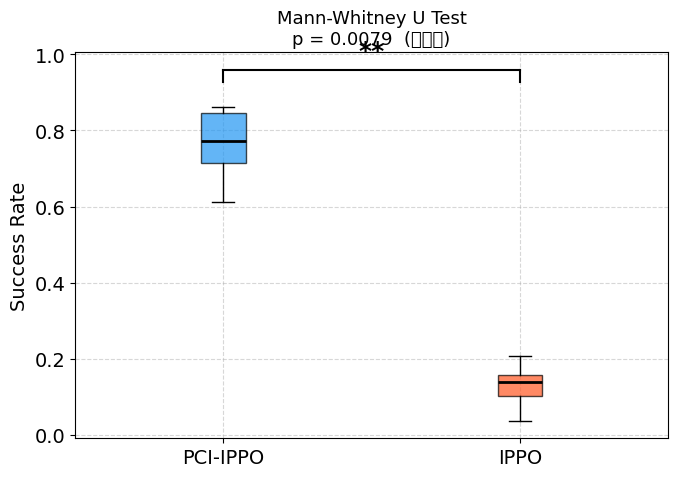

/tmp/ipykernel_2099429/2741144169.py:163: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
/tmp/ipykernel_2099429/2741144169.py:207: UserWarning: Glyph 50976 (\N{HANGUL SYLLABLE YU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2099429/2741144169.py:207: UserWarning: Glyph 51032 (\N{HANGUL SYLLABLE YI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2099429/2741144169.py:207: UserWarning: Glyph 54632 (\N{HANGUL SYLLABLE HAM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chamjin/miniconda3/envs/pcimarl/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 50976 (\N{HANGUL SYLLABLE YU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/chamjin/miniconda3/envs/pcimarl/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: User

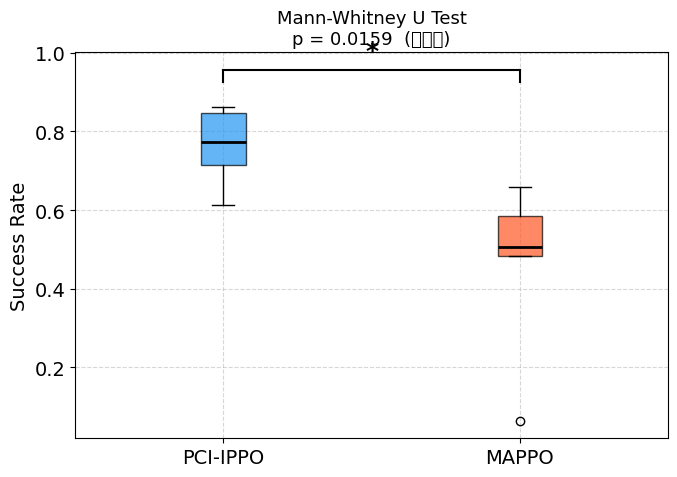

/tmp/ipykernel_2099429/2741144169.py:163: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
/tmp/ipykernel_2099429/2741144169.py:207: UserWarning: Glyph 50976 (\N{HANGUL SYLLABLE YU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2099429/2741144169.py:207: UserWarning: Glyph 51032 (\N{HANGUL SYLLABLE YI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2099429/2741144169.py:207: UserWarning: Glyph 54632 (\N{HANGUL SYLLABLE HAM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chamjin/miniconda3/envs/pcimarl/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 50976 (\N{HANGUL SYLLABLE YU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/chamjin/miniconda3/envs/pcimarl/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: User

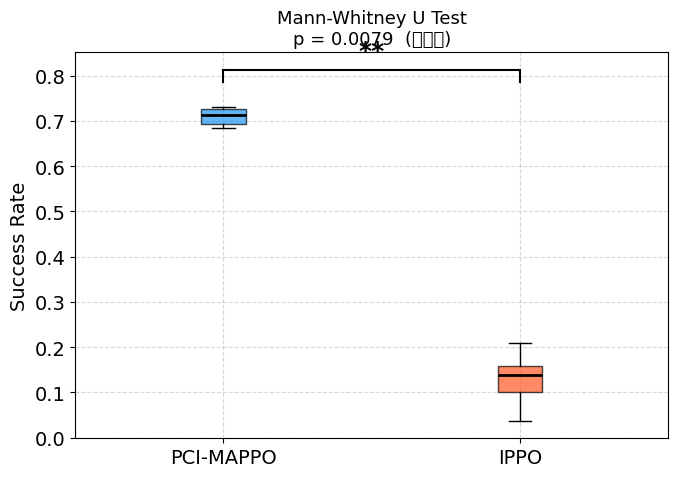

/tmp/ipykernel_2099429/2741144169.py:163: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
/tmp/ipykernel_2099429/2741144169.py:207: UserWarning: Glyph 50976 (\N{HANGUL SYLLABLE YU}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2099429/2741144169.py:207: UserWarning: Glyph 51032 (\N{HANGUL SYLLABLE YI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_2099429/2741144169.py:207: UserWarning: Glyph 54632 (\N{HANGUL SYLLABLE HAM}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/chamjin/miniconda3/envs/pcimarl/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 50976 (\N{HANGUL SYLLABLE YU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/chamjin/miniconda3/envs/pcimarl/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: User

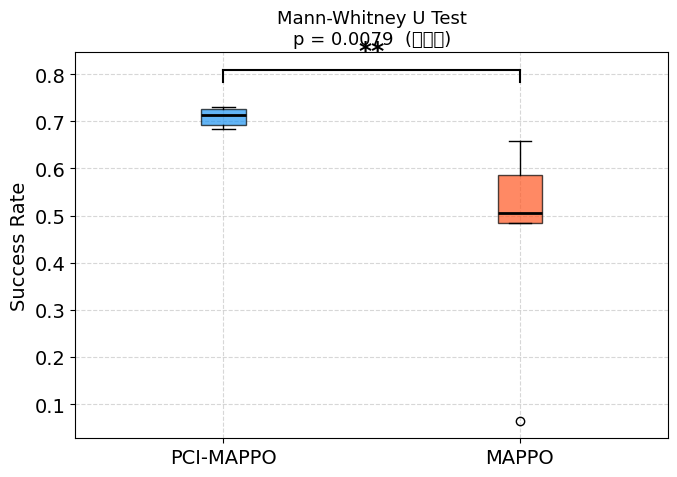


Mann-Whitney U Test Summary
Comparison                N (A, B)        Mean A ± Std       Mean B ± Std       U Stat     p-value    Effect Size  Sig.    
------------------------------------------------------------------------------------------------------------------------
PCI-IPPO vs IPPO          (5, 5)          0.7613±0.0912      0.1290±0.0571      0.0000     0.0079     -1.0000      **      
PCI-IPPO vs MAPPO         (5, 5)          0.7613±0.0912      0.4597±0.2068      1.0000     0.0159     -0.9200      *       
PCI-MAPPO vs IPPO         (5, 5)          0.7091±0.0181      0.1290±0.0571      0.0000     0.0079     -1.0000      **      
PCI-MAPPO vs MAPPO        (5, 5)          0.7091±0.0181      0.4597±0.2068      0.0000     0.0079     -1.0000      **      
Note: *** p<0.001, ** p<0.01, * p<0.05, ns=not significant


In [13]:
import matplotlib.pyplot as plt
import pandas as pd
import os

# ── Mann-Whitney U Test ────────────────────────────────────────────
BASE = 'wandb_csv/SH'

mw_config_pci_ippo = [
    {
        'path':    f'{BASE}/sh3_pci_ippo_r_hat_fact.csv',   # CSV 경로 수정 필요
        'label':   'PCI-IPPO',               # 범례 레이블
        'keyword': 'pci_rippo',                 # 컬럼 키워드
        # 'exclude': None,                      # 제외 키워드 (필요시 주석 해제)
    },
]

mw_config_pci_mappo = [
    {
        'path':    f'{BASE}/sh3_pci_mappo.csv',   # CSV 경로 수정 필요
        'label':   'PCI-MAPPO',              # 범례 레이블
        'keyword': 'pci_rmappo',                 # 컬럼 키워드
        # 'exclude': None,                      # 제외 키워드 (필요시 주석 해제)
    },
]

mw_config_ippo = [
    {
        'path':    f'{BASE}/sh3_ippo.csv',   # CSV 경로 수정 필요
        'label':   'IPPO',
        'keyword': 'ippo',
        # 'exclude': None,
    },
]

mw_config_mappo = [
    {
        'path':    f'{BASE}/sh3_mappo.csv',   # CSV 경로 수정 필요
        'label':   'MAPPO',
        'keyword': 'mappo',
        # 'exclude': None,
    },
]

# Mann-Whitney U 검정 수행 (window_size=50, 마지막 100 포인트 기준)
mw_results_1 = mann_whitney_u_test(
    mw_config_pci_ippo,
    mw_config_ippo,
    window_size=10,
    last_n=200,
    alpha=0.05,
)

mw_results_2 = mann_whitney_u_test(
    mw_config_pci_ippo,
    mw_config_mappo,
    window_size=10,
    last_n=200,
    alpha=0.05,
)

mw_results_3 = mann_whitney_u_test(
    mw_config_pci_mappo,
    mw_config_ippo,
    window_size=10,
    last_n=200,
    alpha=0.05,
)

mw_results_4 = mann_whitney_u_test(
    mw_config_pci_mappo,
    mw_config_mappo,
    window_size=10,
    last_n=200,
    alpha=0.05,
)

mw_results = [mw_results_1, mw_results_2, mw_results_3, mw_results_4]

# 박스플롯 시각화
for result in mw_results:
    if result is not None:
        plot_mann_whitney(result)

# ── 개선된 Table 형식 (RL Paper 표준) ────────────────────────────────────
print('\n' + '='*120)
print('Mann-Whitney U Test Summary')
print('='*120)

# 헤더 출력
header = f'{"Comparison":<25} {"N (A, B)":<15} {"Mean A ± Std":<18} {"Mean B ± Std":<18} {"U Stat":<10} {"p-value":<10} {"Effect Size":<12} {"Sig.":<8}'
print(header)
print('-'*120)

# 결과 테이블 출력
for i, result in enumerate(mw_results):
    if result is not None:
        comparison = f"{result['label_a']} vs {result['label_b']}"
        n_info = f"({result['n_a']}, {result['n_b']})"
        mean_a_str = f"{result['mean_a']:.4f}±{result['std_a']:.4f}"
        mean_b_str = f"{result['mean_b']:.4f}±{result['std_b']:.4f}"
        u_stat = f"{result['stat']:.4f}"
        p_value = f"{result['p_value']:.4f}"
        effect_size = f"{result['effect_size']:.4f}"
        
        # p-value 기반 유의성 표시
        if result['p_value'] < 0.001:
            sig_marker = '***'
        elif result['p_value'] < 0.01:
            sig_marker = '**'
        elif result['p_value'] < 0.05:
            sig_marker = '*'
        else:
            sig_marker = 'ns'
        
        print(f'{comparison:<25} {n_info:<15} {mean_a_str:<18} {mean_b_str:<18} {u_stat:<10} {p_value:<10} {effect_size:<12} {sig_marker:<8}')

print('='*120)
print('Note: *** p<0.001, ** p<0.01, * p<0.05, ns=not significant')
print('='*120)